## 03 — PCA Analysis
Dimensionality analysis of extracted features. Addresses the question: how many independent dimensions of variation exist in the ~3700-feature space, and does the first PC separate high-AOD from low-AOD scenes?

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.decomposition import PCA

ROOT     = Path('D:/Regional-Scale-AOD-Estimation')
FEATURES = ROOT / 'feature_engineering/features/stratified'
OUT      = ROOT / 'feature_engineering/features_analysis/pca'
OUT.mkdir(parents=True, exist_ok=True)

TARGET = 'AOD_550nm'

In [8]:
train     = pd.read_csv(FEATURES / 'train.csv')
feat_cols = [c for c in train.columns if c != TARGET]
X_train   = train[feat_cols].values
y_train   = train[TARGET].values

assert not np.isnan(X_train).any(), "NaNs in X_train"
assert not np.isinf(X_train).any(), "Infs in X_train"
print(f'X_train: {X_train.shape} | AOD range: [{y_train.min():.3f}, {y_train.max():.3f}]')

X_train: (4099, 3700) | AOD range: [0.008, 2.928]


In [9]:
pca    = PCA(random_state=42)
pca.fit(X_train)
cumvar = np.cumsum(pca.explained_variance_ratio_)

n_90 = int(np.searchsorted(cumvar, 0.90, side='left')) + 1
n_95 = int(np.searchsorted(cumvar, 0.95, side='left')) + 1
n_99 = int(np.searchsorted(cumvar, 0.99, side='left')) + 1

print(f'Total features: {X_train.shape[1]}')
print(f'90% variance: {n_90} components  ({n_90/X_train.shape[1]*100:.1f}% of features, {X_train.shape[1]/n_90:.1f}x compression)')
print(f'95% variance: {n_95} components  ({n_95/X_train.shape[1]*100:.1f}% of features, {X_train.shape[1]/n_95:.1f}x compression)')
print(f'99% variance: {n_99} components  ({n_99/X_train.shape[1]*100:.1f}% of features, {X_train.shape[1]/n_99:.1f}x compression)')
print(f'PC1 explains: {pca.explained_variance_ratio_[0]*100:.2f}%')
print(f'PC2 explains: {pca.explained_variance_ratio_[1]*100:.2f}%')

Total features: 3700
90% variance: 13 components  (0.4% of features, 284.6x compression)
95% variance: 29 components  (0.8% of features, 127.6x compression)
99% variance: 150 components  (4.1% of features, 24.7x compression)
PC1 explains: 41.00%
PC2 explains: 19.81%


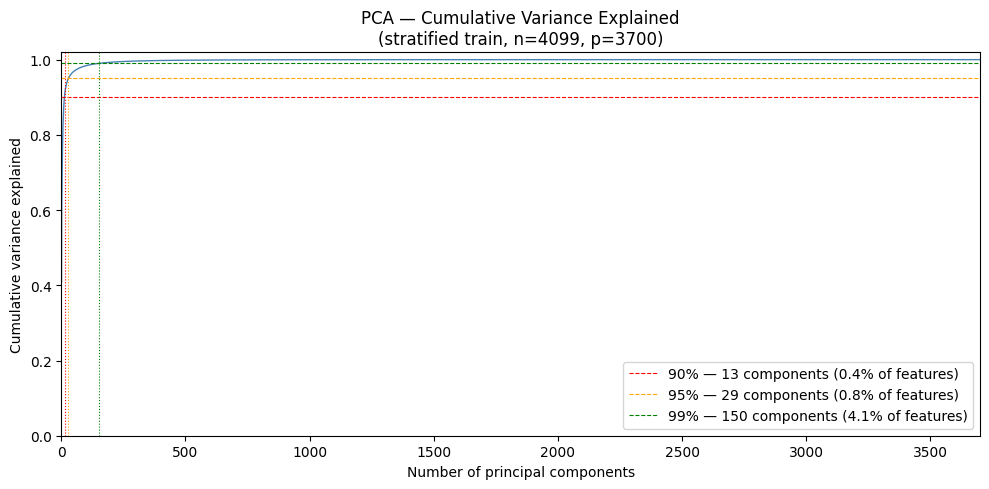

Saved: D:\Regional-Scale-AOD-Estimation\feature_engineering\features_analysis\pca/cumulative_variance.png


In [10]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(np.arange(1, len(cumvar) + 1), cumvar, linewidth=1, color='steelblue')
for thresh, n, colour, ls in [(0.90, n_90, 'red', '--'),
                               (0.95, n_95, 'orange', '--'),
                               (0.99, n_99, 'green', '--')]:
    ax.axhline(thresh, color=colour, linestyle=ls, linewidth=0.8,
               label=f'{int(thresh*100)}% — {n} components ({n/X_train.shape[1]*100:.1f}% of features)')
    ax.axvline(n, color=colour, linestyle=':', linewidth=0.8)
ax.set_xlabel('Number of principal components')
ax.set_ylabel('Cumulative variance explained')
ax.set_title('PCA — Cumulative Variance Explained\n(stratified train, n=4099, p=3700)')
ax.legend(loc='lower right')
ax.set_xlim(0, X_train.shape[1])
ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.savefig(OUT / 'cumulative_variance.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {OUT}/cumulative_variance.png')

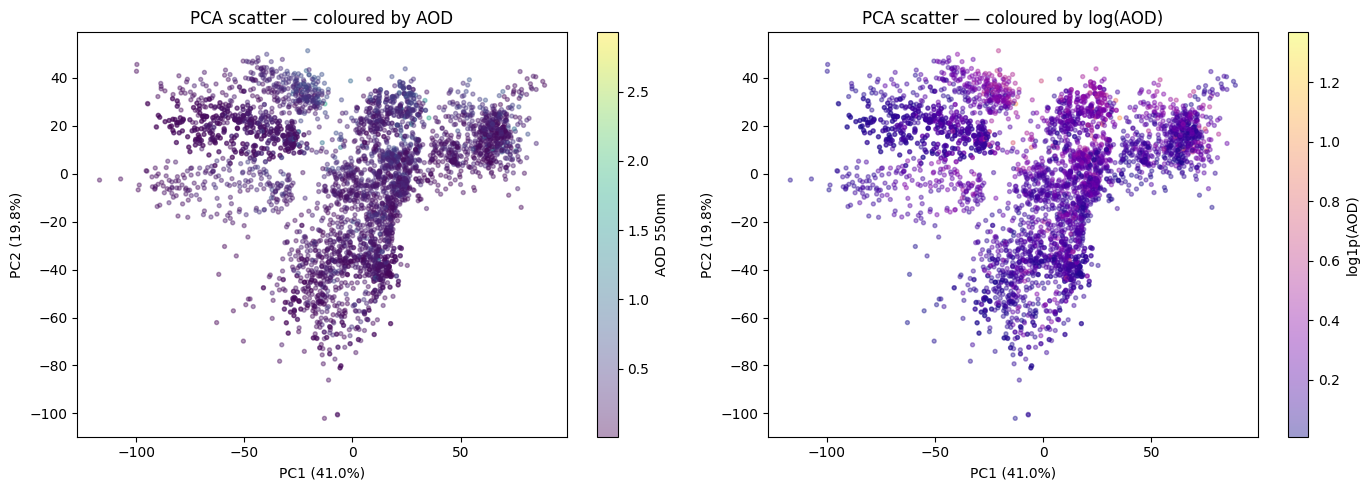

Saved: D:\Regional-Scale-AOD-Estimation\feature_engineering\features_analysis\pca/pca_scatter_aod.png


In [11]:
X_2d = pca.transform(X_train)[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sc = axes[0].scatter(X_2d[:, 0], X_2d[:, 1],
                     c=y_train, cmap='viridis', alpha=0.4, s=8)
plt.colorbar(sc, ax=axes[0], label='AOD 550nm')
axes[0].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[0].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[0].set_title('PCA scatter — coloured by AOD')

sc2 = axes[1].scatter(X_2d[:, 0], X_2d[:, 1],
                      c=np.log1p(y_train), cmap='plasma', alpha=0.4, s=8)
plt.colorbar(sc2, ax=axes[1], label='log1p(AOD)')
axes[1].set_xlabel(f'PC1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
axes[1].set_ylabel(f'PC2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
axes[1].set_title('PCA scatter — coloured by log(AOD)')

plt.tight_layout()
plt.savefig(OUT / 'pca_scatter_aod.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {OUT}/pca_scatter_aod.png')

In [12]:
summary = pd.DataFrame({
    'variance_threshold': [0.90, 0.95, 0.99],
    'n_components':       [n_90, n_95, n_99],
    'pct_of_features':    [round(n/X_train.shape[1]*100, 2) for n in [n_90, n_95, n_99]],
    'compression_ratio':  [round(X_train.shape[1]/n, 2)     for n in [n_90, n_95, n_99]],
})
summary.to_csv(OUT / 'pca_summary.csv', index=False)
print('Saved: pca_summary.csv')
print(summary.to_string(index=False))

Saved: pca_summary.csv
 variance_threshold  n_components  pct_of_features  compression_ratio
               0.90            13             0.35             284.62
               0.95            29             0.78             127.59
               0.99           150             4.05              24.67
